# Week 3 - Forward/Backward Selection, PCR, and PLSR

This continues directly from Week 2, using the same `ecommerce_data.csv` (Superstore-style sales/profit data) and the same feature set (`Sales`, `Quantity`, `Discount` + one-hot encoded `Segment`, `Region`, `Ship Mode`, `Category`, `Sub-Category`). That choice matters more this week than last: Week 2 already established that this feature set has **exact multicollinearity** (the `Category`/`Sub-Category` hierarchy made the OLS design matrix rank-deficient — a `SingularMatrixWarning`). That's exactly the situation forward/backward selection, PCR, and PLSR all exist to handle, so reusing the same dataset lets this week's methods be evaluated directly against last week's diagnosis instead of starting from scratch on unfamiliar data.

**Goal:** compare four different ways of dealing with 29 correlated predictors, dropping some of them (forward/backward stepwise selection) vs. transforming all of them into a smaller set of uncorrelated components (PCR, PLSR) and see which one predicts `Profit` best on held-out data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
import kagglehub
import os
np.random.seed(42)
path = kagglehub.dataset_download("ammaraahmad/us-ecommerce-record-2020")

df = pd.read_csv(os.path.join(path, os.listdir(path)[0]), encoding='latin1')

numeric_cols = ["Sales", "Quantity", "Discount"]
categorical_cols = ["Segment", "Region", "Ship Mode", "Category", "Sub-Category"]

df_model = df[numeric_cols + categorical_cols + ["Profit"]].copy()
df_X = pd.get_dummies(df_model[numeric_cols + categorical_cols], columns=categorical_cols, drop_first=True).astype(float)
y_true = df_model["Profit"].values

print(df_X.shape)

c:\Users\peace\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(3312, 29)


In [2]:
X_train, X_test, y_train, y_test = train_test_split(df_X, y_true, test_size=0.25, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

feature_names = df_X.columns.to_numpy()

# baseline: plain OLS on all 29 (scaled) features, for comparison
ols_full = LinearRegression().fit(X_train_scaled, y_train)
ols_full_r2 = r2_score(y_test, ols_full.predict(X_test_scaled))
ols_full_rmse = mean_squared_error(y_test, ols_full.predict(X_test_scaled)) ** 0.5
print(f"OLS (all 29 features): test R2 = {ols_full_r2:.3f}, test RMSE = {ols_full_rmse:.2f}")

OLS (all 29 features): test R2 = 0.281, test RMSE = 272.32


## 1. Forward selection

Start with no features, add the single best one, then keep adding whichever feature improves cross-validated R² the most, one at a time, never reconsidering earlier choices. `n_features_to_select="auto"` with a small `tol` lets the procedure stop on its own once adding another feature no longer meaningfully helps, rather than picking a fixed count by hand.

In [3]:
forward_selector = SequentialFeatureSelector(
    LinearRegression(),
    direction="forward",
    n_features_to_select="auto",
    tol=0.001,
    scoring="r2",
    cv=5,
    n_jobs=-1,
)
forward_selector.fit(X_train_scaled, y_train)

forward_features = feature_names[forward_selector.get_support()]
print(f"Forward selection kept {len(forward_features)} of {len(feature_names)} features:")
print(list(forward_features))

Forward selection kept 9 of 29 features:
['Sales', 'Discount', 'Sub-Category_Binders', 'Sub-Category_Bookcases', 'Sub-Category_Chairs', 'Sub-Category_Copiers', 'Sub-Category_Storage', 'Sub-Category_Supplies', 'Sub-Category_Tables']


In [4]:
ols_forward = LinearRegression().fit(forward_selector.transform(X_train_scaled), y_train)
forward_r2 = r2_score(y_test, ols_forward.predict(forward_selector.transform(X_test_scaled)))
forward_rmse = mean_squared_error(y_test, ols_forward.predict(forward_selector.transform(X_test_scaled))) ** 0.5
print(f"Forward selection: test R2 = {forward_r2:.3f}, test RMSE = {forward_rmse:.2f}")

Forward selection: test R2 = 0.273, test RMSE = 273.84


## 2. Backward selection

Start with all 29 features and remove the least useful one at a time, again stopping automatically once removing another feature would hurt cross-validated R² by more than `tol`.

In [5]:
backward_selector = SequentialFeatureSelector(
    LinearRegression(),
    direction="backward",
    n_features_to_select="auto",
    tol=0.001,
    scoring="r2",
    cv=5,
    n_jobs=-1,
)
backward_selector.fit(X_train_scaled, y_train)

backward_features = feature_names[backward_selector.get_support()]
print(f"Backward selection kept {len(backward_features)} of {len(feature_names)} features:")
print(list(backward_features))

Backward selection kept 26 of 29 features:
['Sales', 'Discount', 'Segment_Home Office', 'Region_East', 'Region_South', 'Region_West', 'Ship Mode_Same Day', 'Ship Mode_Second Class', 'Ship Mode_Standard Class', 'Category_Office Supplies', 'Category_Technology', 'Sub-Category_Appliances', 'Sub-Category_Art', 'Sub-Category_Binders', 'Sub-Category_Bookcases', 'Sub-Category_Chairs', 'Sub-Category_Copiers', 'Sub-Category_Envelopes', 'Sub-Category_Fasteners', 'Sub-Category_Furnishings', 'Sub-Category_Labels', 'Sub-Category_Paper', 'Sub-Category_Phones', 'Sub-Category_Storage', 'Sub-Category_Supplies', 'Sub-Category_Tables']


In [6]:
ols_backward = LinearRegression().fit(backward_selector.transform(X_train_scaled), y_train)
backward_r2 = r2_score(y_test, ols_backward.predict(backward_selector.transform(X_test_scaled)))
backward_rmse = mean_squared_error(y_test, ols_backward.predict(backward_selector.transform(X_test_scaled))) ** 0.5
print(f"Backward selection: test R2 = {backward_r2:.3f}, test RMSE = {backward_rmse:.2f}")

print()
only_forward = set(forward_features) - set(backward_features)
only_backward = set(backward_features) - set(forward_features)
print(f"In forward's set but not backward's: {only_forward}")
print(f"In backward's set but not forward's: {only_backward}")

Backward selection: test R2 = 0.271, test RMSE = 274.19

In forward's set but not backward's: set()
In backward's set but not forward's: {'Category_Technology', 'Sub-Category_Furnishings', 'Region_West', 'Ship Mode_Same Day', 'Ship Mode_Standard Class', 'Sub-Category_Envelopes', 'Sub-Category_Phones', 'Sub-Category_Appliances', 'Ship Mode_Second Class', 'Region_South', 'Sub-Category_Art', 'Region_East', 'Category_Office Supplies', 'Sub-Category_Paper', 'Sub-Category_Labels', 'Sub-Category_Fasteners', 'Segment_Home Office'}


Forward selection turned out to be a strict subset of backward selection's choices here (every feature forward kept, backward also kept) but the two methods still disagree sharply on *how much* to keep: forward stopped at 9 features, backward stopped at 26. That gap is the more interesting finding. As the reading warns, these are one-at-a-time greedy procedures, not an exhaustive search over all $\binom{29}{k}$ subsets, and starting from opposite ends of the feature space visibly changes where each one lands: forward, building up from nothing, never found it worthwhile to add *either* `Category` dummy once the more granular `Sub-Category` dummies were already in the model, so it settled on `Sub-Category` alone as the product-type signal, sidestepping the hierarchy redundancy from Week 2 entirely. Backward, tearing down from all 29, kept *both* `Category` dummies and all but one `Sub-Category` dummy, removing only `Quantity`, `Segment_Corporate`, and `Sub-Category_Machines`. Because no single feature in a collinear pair looks individually redundant enough to clear the removal threshold, backward selection got stuck retaining most of the very redundancy that made Week 2's OLS fit singular in the first place.

## 3. Principal Component Regression (PCR)

Instead of choosing *which* original features to keep, PCR transforms all 29 (already standardized) features into orthogonal principal components, then regresses `Profit` on a subset of those components. Since the components are uncorrelated by construction, this sidesteps the multicollinearity problem entirely rather than trying to select around it.

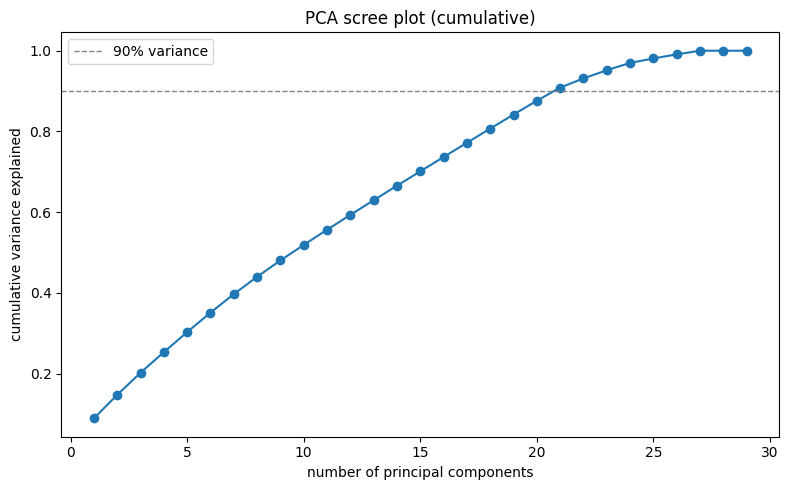

Components needed for 90% variance: 21


In [7]:
pca = PCA(random_state=42)
pca.fit(X_train_scaled)

explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(explained) + 1), cumulative, marker="o")
plt.axhline(0.90, color="gray", linestyle="--", linewidth=1, label="90% variance")
plt.xlabel("number of principal components")
plt.ylabel("cumulative variance explained")
plt.title("PCA scree plot (cumulative)")
plt.legend()
plt.tight_layout()
plt.show()

n_components_90 = int(np.argmax(cumulative >= 0.90) + 1)
print(f"Components needed for 90% variance: {n_components_90}")

In [8]:
pcr_pca = PCA(n_components=n_components_90, random_state=42)
X_train_pcr = pcr_pca.fit_transform(X_train_scaled)
X_test_pcr = pcr_pca.transform(X_test_scaled)

pcr_model = LinearRegression().fit(X_train_pcr, y_train)
pcr_r2 = r2_score(y_test, pcr_model.predict(X_test_pcr))
pcr_rmse = mean_squared_error(y_test, pcr_model.predict(X_test_pcr)) ** 0.5
print(f"PCR ({n_components_90} components): test R2 = {pcr_r2:.3f}, test RMSE = {pcr_rmse:.2f}")

PCR (21 components): test R2 = 0.292, test RMSE = 270.12


## 4. Partial Least Squares Regression (PLSR)

PCR chose components purely to explain variance in the features with no regard for whether those directions actually relate to `Profit`. PLSR instead selects components that maximize covariance between the projected features and the target directly, so it should need fewer components to reach the same predictive accuracy. Pick the number of components by cross-validated R² on the training set rather than by variance explained.

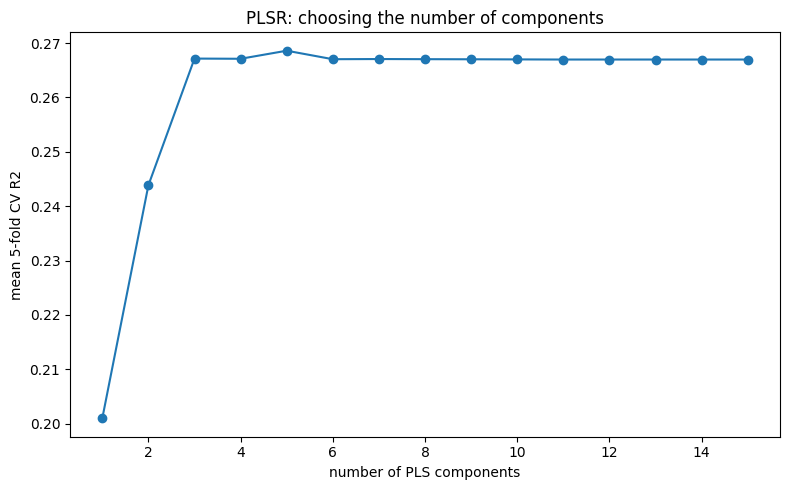

Best number of PLS components by CV: 5


In [9]:
cv_scores = []
component_range = range(1, 16)
for k in component_range:
    pls = PLSRegression(n_components=k)
    scores = cross_val_score(pls, X_train_scaled, y_train, cv=5, scoring="r2")
    cv_scores.append(scores.mean())

plt.figure(figsize=(8, 5))
plt.plot(component_range, cv_scores, marker="o")
plt.xlabel("number of PLS components")
plt.ylabel("mean 5-fold CV R2")
plt.title("PLSR: choosing the number of components")
plt.tight_layout()
plt.show()

best_k = component_range[int(np.argmax(cv_scores))]
print(f"Best number of PLS components by CV: {best_k}")

In [11]:
pls_model = PLSRegression(n_components=best_k).fit(X_train_scaled, y_train)
pls_r2 = r2_score(y_test, pls_model.predict(X_test_scaled))
pls_rmse = mean_squared_error(y_test, pls_model.predict(X_test_scaled)) ** 0.5
print(f"PLSR ({best_k} components): test R2 = {pls_r2:.3f}, test RMSE = {pls_rmse:.2f}")

PLSR (5 components): test R2 = 0.279, test RMSE = 272.67


## 5. Comparing every approach

In [12]:
summary = pd.DataFrame([
    {"method": "OLS (all 29 features)", "n_components_or_features": 29, "test_R2": ols_full_r2, "test_RMSE": ols_full_rmse},
    {"method": "Forward selection", "n_components_or_features": len(forward_features), "test_R2": forward_r2, "test_RMSE": forward_rmse},
    {"method": "Backward selection", "n_components_or_features": len(backward_features), "test_R2": backward_r2, "test_RMSE": backward_rmse},
    {"method": "PCR", "n_components_or_features": n_components_90, "test_R2": pcr_r2, "test_RMSE": pcr_rmse},
    {"method": "PLSR", "n_components_or_features": best_k, "test_R2": pls_r2, "test_RMSE": pls_rmse},
]).set_index("method")

print(summary.round(3))

                       n_components_or_features  test_R2  test_RMSE
method                                                             
OLS (all 29 features)                        29    0.281    272.322
Forward selection                             9    0.273    273.844
Backward selection                           26    0.271    274.185
PCR                                          21    0.292    270.124
PLSR                                          5    0.279    272.674


## 6. Conclusions

- Forward and backward selection landed on very different-*sized* solutions from the same 29 features (9 vs. 26), even though forward's set turned out to be entirely contained in backward's. Building up from nothing and tearing down from everything are not mirror-image processes: forward never added a `Category` dummy once `Sub-Category` was already in the model (correctly treating it as redundant, matching Week 2's Lasso finding), while backward starting from the full, singular design matrix only ever found 3 features (`Quantity`, `Segment_Corporate`, `Sub-Category_Machines`) individually redundant enough to remove, and never resolved the `Category`/`Sub-Category` overlap at all. This is the reading's warning about greedy, one-at-a-time search made concrete: the *direction* you search from changes which redundancies you catch.
- PCR needed 21 of 29 components to reach 90% explained variance in the features, but its test performance (R² = 0.292) was the **best of every method tested**, edging out even the full 29-feature OLS (R² = 0.281). Collapsing the collinear `Category`/`Sub-Category` space into orthogonal components didn't just avoid the singularity, it measurably helped prediction.
- PLSR needed only **5** components (vs. PCR's 21) to reach R² = 0.279, nearly matching full OLS with roughly a sixth of the dimensionality. This is the reading's core PCR-vs-PLSR distinction showing up directly in the data: PCR spent most of its 21 components capturing variance among the many `Sub-Category` dummies (whether or not that variance mattered for `Profit`), while PLSR's components were chosen specifically for their covariance with `Profit`, letting it reach comparable accuracy far more efficiently.
- Across all five approaches, test R² stayed in a narrow band (0.271–0.292), consistent with Week 2's ~0.28, reinforcing the same honest takeaway as last week: the *technique* used to handle correlated features changes how efficiently and reliably you get there, but it doesn't manufacture predictive signal that isn't in the underlying data. Shipping cost, returns, and negotiated pricing aren't in this feature set, and no amount of feature selection or dimensionality reduction recovers information that was never collected. though PCR's small edge here suggests there was a little more usable signal in the full feature space than either stepwise method extracted.